# Assignment 2
## Part A Task definition and volume inspection

### A.1 config

In [1]:
%pip install nibabel

Note: you may need to restart the kernel to use updated packages.

In [2]:
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import copy
import itertools
import json
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import nibabel as nib
from nibabel.processing import resample_to_output
from scipy import ndimage
from scipy.stats import wilcoxon
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

DATA_ROOT = Path("Task01_BrainTumour")
SPLIT_FILE = Path("assignment2_split.csv")
CACHE_DIR = Path("cache")
MODEL_DIR = Path("models")
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)
print("Device:", DEVICE, "| PyTorch:", torch.__version__, "| nibabel:", nib.__version__)

Device: mps | PyTorch: 2.14.0 | nibabel: 5.4.2


In [3]:
with open(DATA_ROOT / "dataset.json") as file:
    dataset_info = json.load(file)
MODALITIES = [dataset_info["modality"][str(i)] for i in range(len(dataset_info["modality"]))]
LABEL_NAMES = {int(key): value for key, value in dataset_info["labels"].items()}
print("Channel order:", dataset_info["modality"])
print("Label values:", dataset_info["labels"])
print("Labelled cases:", dataset_info["numTraining"], "| unlabelled official test cases (not used):", dataset_info["numTest"])

split_df = pd.read_csv(SPLIT_FILE)
print("Cases in split file:", len(split_df))

Channel order: {'0': 'FLAIR', '1': 'T1w', '2': 't1gd', '3': 'T2w'}
Label values: {'0': 'background', '1': 'edema', '2': 'non-enhancing tumor', '3': 'enhancing tumour'}
Labelled cases: 484 | unlabelled official test cases (not used): 266
Cases in split file: 484


### A.2 geometry of three cases

In [4]:
def image_path(case_id):
    return DATA_ROOT / "imagesTr" / f"{case_id}.nii.gz"


def label_path(case_id):
    return DATA_ROOT / "labelsTr" / f"{case_id}.nii.gz"


inspect_ids = split_df.loc[split_df["split"] == "train", "case_id"].head(3).tolist()
rows = []
for case_id in inspect_ids:
    image_nii = nib.load(image_path(case_id))
    label_nii = nib.load(label_path(case_id))
    values, counts = np.unique(np.asarray(label_nii.dataobj), return_counts=True)
    rows.append({
        "case_id": case_id,
        "image shape": image_nii.shape,
        "image dtype": str(image_nii.get_data_dtype()),
        "label shape": label_nii.shape,
        "orientation": "".join(nib.aff2axcodes(image_nii.affine)),
        "spacing (mm)": tuple(round(float(s), 3) for s in image_nii.header.get_zooms()[:3]),
        "sform/qform code": (int(image_nii.header["sform_code"]), int(image_nii.header["qform_code"])),
        "label values (voxels)": dict(zip(values.astype(int).tolist(), counts.tolist())),
        "same affine": bool(np.allclose(image_nii.affine, label_nii.affine)),
    })
    print(case_id, "affine:")
    print(image_nii.affine)
pd.DataFrame(rows).set_index("case_id")

BRATS_001 affine:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
BRATS_003 affine:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
BRATS_004 affine:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]


,image shape,image dtype,label shape,orientation,spacing (mm),sform/qform code,label values (voxels),same affine
case_id,,,,,,,,
BRATS_001,"(240, 240, 155, 4)",float32,"(240, 240, 155)",RAS,"(1.0, 1.0, 1.0)","(1, 1)","{0: 8816276, 1: 53050, 2: 27189, 3: 31485}",True
BRATS_003,"(240, 240, 155, 4)",float32,"(240, 240, 155)",RAS,"(1.0, 1.0, 1.0)","(1, 1)","{0: 8754073, 1: 148263, 2: 4414, 3: 21250}",True
BRATS_004,"(240, 240, 155, 4)",float32,"(240, 240, 155)",RAS,"(1.0, 1.0, 1.0)","(1, 1)","{0: 8807340, 1: 45189, 2: 57655, 3: 17816}",True


In [5]:
def load_image(case_id):
    image_nii = nib.as_closest_canonical(nib.load(image_path(case_id)))
    return np.moveaxis(image_nii.get_fdata(dtype=np.float32), -1, 0), image_nii.affine


def load_label(case_id):
    label_nii = nib.as_closest_canonical(nib.load(label_path(case_id)))
    return np.asarray(label_nii.dataobj).astype(np.uint8), label_nii.affine


example_id = inspect_ids[0]
example_volume, example_affine = load_image(example_id)
example_label, example_label_affine = load_label(example_id)
spacing = np.array(nib.affines.voxel_sizes(example_affine))
codes = nib.aff2axcodes(example_affine)

label_centre = np.round(np.argwhere(example_label > 0).mean(axis=0)).astype(int)
centre_mm = nib.affines.apply_affine(example_label_affine, label_centre)
image_centre = np.round(nib.affines.apply_affine(np.linalg.inv(example_affine), centre_mm)).astype(int)
print("Model input array [C, X, Y, Z]:", example_volume.shape, "| label:", example_label.shape)
print("Tumour centre: label voxel", label_centre, "-> world", centre_mm.round(1), "mm -> image voxel", image_centre)

Model input array [C, X, Y, Z]: (4, 240, 240, 155) | label: (240, 240, 155)
Tumour centre: label voxel [157 116  67] -> world [157. 116.  67.] mm -> image voxel [157 116  67]


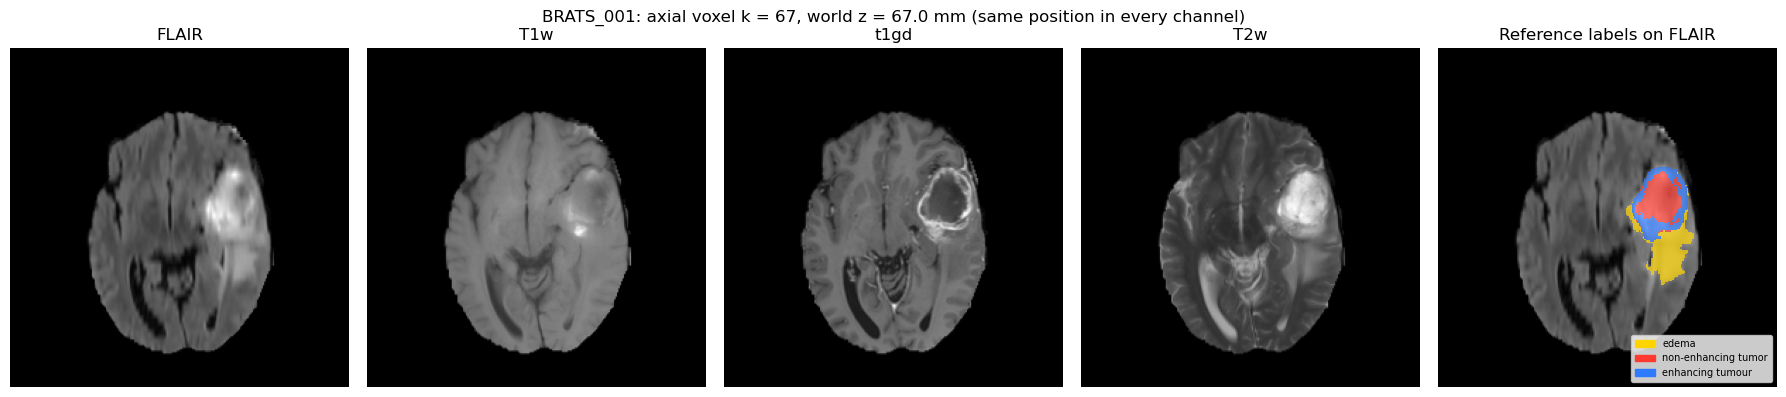

In [6]:
LABEL_COLOURS = ListedColormap(["#ffd400", "#ff3b30", "#2f7bff"])

k = image_centre[2]
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, name, channel in zip(axes, MODALITIES, example_volume):
    ax.imshow(channel[:, :, k].T, cmap="gray", origin="lower")
    ax.set_title(name)
axes[4].imshow(example_volume[0][:, :, k].T, cmap="gray", origin="lower")
axes[4].imshow(np.ma.masked_equal(example_label[:, :, k], 0).T, cmap=LABEL_COLOURS, vmin=0.5, vmax=3.5,
               origin="lower", alpha=0.7, interpolation="nearest")
axes[4].set_title("Reference labels on FLAIR")
axes[4].legend(handles=[Patch(color=LABEL_COLOURS(i), label=LABEL_NAMES[i + 1]) for i in range(3)],
               loc="lower right", fontsize=7)
for ax in axes:
    ax.axis("off")
fig.suptitle(f"{example_id}: axial voxel k = {k}, world z = {centre_mm[2]:.1f} mm (same position in every channel)")
plt.tight_layout()
plt.show()

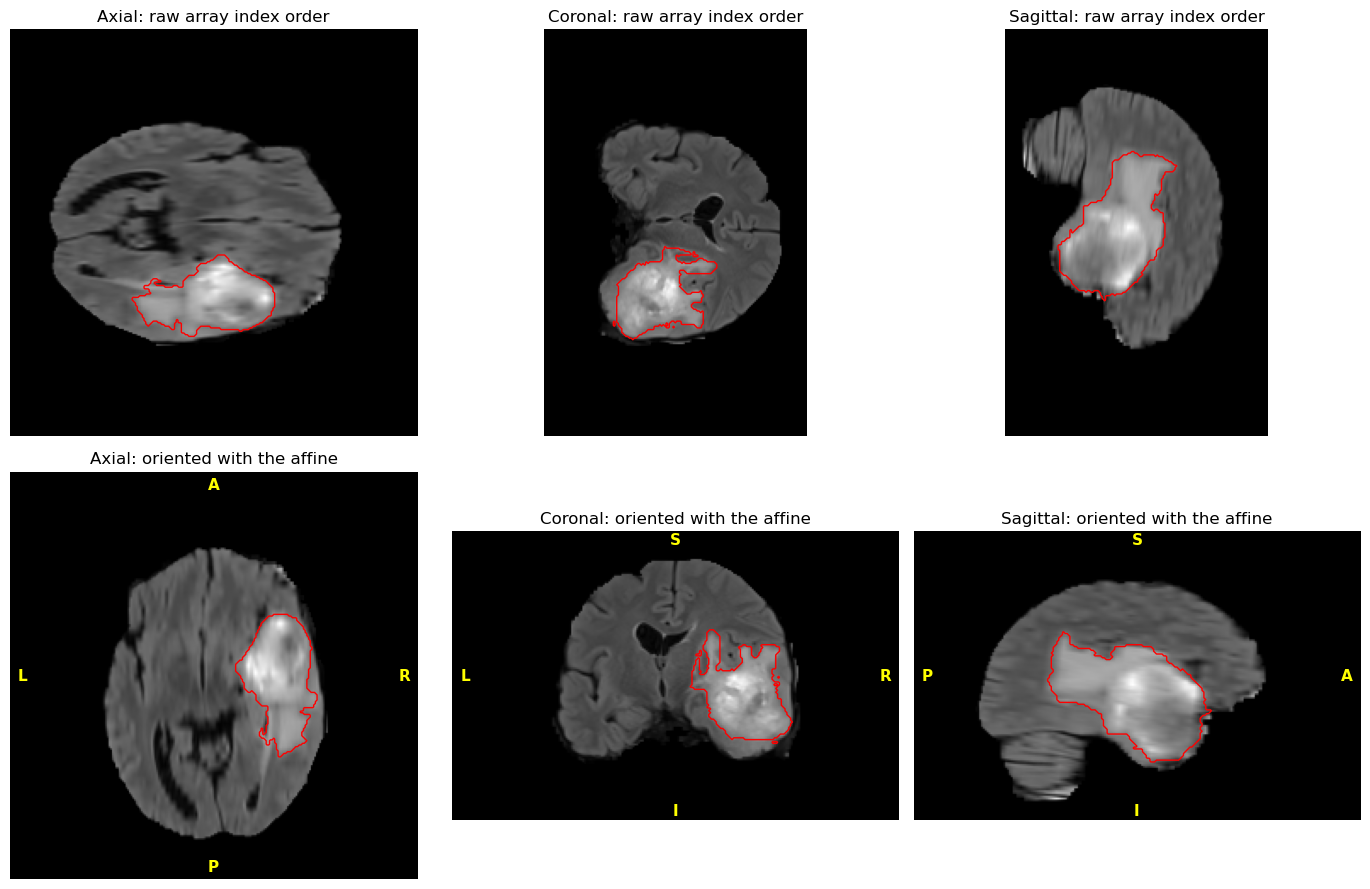

In [7]:
OPPOSITE = {"R": "L", "L": "R", "A": "P", "P": "A", "S": "I", "I": "S"}
PLANES = {"Axial": (2, (0, 1)), "Coronal": (1, (0, 2)), "Sagittal": (0, (1, 2))}


def take_slice(array, plane, centre):
    fixed_axis, _ = PLANES[plane]
    return np.take(array, centre[fixed_axis], axis=fixed_axis)


def show_plane(ax, background, plane, centre, spacing, codes, contour=None, overlay=None, vmax=None):
    _, (h_axis, v_axis) = PLANES[plane]
    aspect = spacing[v_axis] / spacing[h_axis]
    ax.imshow(take_slice(background, plane, centre).T, cmap="gray", origin="lower", aspect=aspect, vmax=vmax)
    if contour is not None:
        ax.contour(take_slice(contour, plane, centre).T, levels=[0.5], colors="red", linewidths=1)
    if overlay is not None:
        ax.imshow(np.swapaxes(take_slice(overlay, plane, centre), 0, 1), origin="lower", aspect=aspect,
                  interpolation="nearest")
    for x, y, letter in [(0.03, 0.5, OPPOSITE[codes[h_axis]]), (0.97, 0.5, codes[h_axis]),
                         (0.5, 0.03, OPPOSITE[codes[v_axis]]), (0.5, 0.97, codes[v_axis])]:
        ax.text(x, y, letter, transform=ax.transAxes, color="yellow", ha="center", va="center", fontsize=11,
                weight="bold")
    ax.axis("off")


example_tumour = (example_label > 0).astype(np.uint8)
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for column, plane in enumerate(PLANES):
    axes[0, column].imshow(take_slice(example_volume[0], plane, image_centre), cmap="gray")
    axes[0, column].contour(take_slice(example_tumour, plane, image_centre), levels=[0.5], colors="red",
                            linewidths=1)
    axes[0, column].set_title(f"{plane}: raw array index order")
    axes[0, column].axis("off")
    show_plane(axes[1, column], example_volume[0], plane, image_centre, spacing, codes, contour=example_tumour)
    axes[1, column].set_title(f"{plane}: oriented with the affine")
plt.tight_layout()
plt.show()

## Part B Case-level split

In [8]:
split_df = pd.read_csv(SPLIT_FILE)
assert len(split_df) == 484
assert set(split_df["split"]) == {"train", "validation", "test"}
assert split_df["case_id"].is_unique

missing = []
for row in split_df.itertuples():
    for relpath in [row.image_relpath, row.label_relpath]:
        if not (DATA_ROOT / relpath).exists():
            missing.append(relpath)
    assert Path(row.image_relpath).name == Path(row.label_relpath).name == f"{row.case_id}.nii.gz"
print("Listed files missing on disk:", len(missing))
assert not missing

images_on_disk = {path.name for path in (DATA_ROOT / "imagesTr").glob("BRATS_*.nii.gz")}
labels_on_disk = {path.name for path in (DATA_ROOT / "labelsTr").glob("BRATS_*.nii.gz")}
listed = set(split_df["image_relpath"].map(lambda relpath: Path(relpath).name))
print("Images on disk:", len(images_on_disk), "| labels on disk:", len(labels_on_disk),
      "| on disk but not listed:", len((images_on_disk | labels_on_disk) - listed))
print(split_df["split"].value_counts())

Listed files missing on disk: 0
Images on disk: 484 | labels on disk: 484 | on disk but not listed: 0
split
train         338
test           73
validation     73
Name: count, dtype: int64


In [9]:
def check_disjoint(split_ids):
    for first, second in itertools.combinations(["train", "validation", "test"], 2):
        shared = split_ids[first] & split_ids[second]
        assert not shared, f"{first} and {second} share {len(shared)} case(s)"


split_ids = {split: set(group["case_id"]) for split, group in split_df.groupby("split")}
check_disjoint(split_ids)
assert sum(len(ids) for ids in split_ids.values()) == split_df["case_id"].nunique()
print("Train / validation / test cases:", len(split_ids["train"]), len(split_ids["validation"]), len(split_ids["test"]))
print("No case appears in more than one split.")

leaky_ids = {**split_ids, "test": split_ids["test"] | {sorted(split_ids["train"])[0]}}
try:
    check_disjoint(leaky_ids)
except AssertionError as error:
    print("Injected leak detected:", error)

Train / validation / test cases: 338 73 73
No case appears in more than one split.
Injected leak detected: train and test share 1 case(s)


In [10]:
def flair_fingerprint(case_id):
    flair = np.asarray(nib.load(image_path(case_id)).dataobj[..., 0])[::3, ::3, ::3].astype(np.float32)
    brain = flair != 0
    fingerprint = np.zeros_like(flair)
    fingerprint[brain] = (flair[brain] - flair[brain].mean()) / flair[brain].std()
    return fingerprint.ravel() / np.linalg.norm(fingerprint)


with ThreadPoolExecutor(8) as pool:
    fingerprints = np.stack(list(pool.map(flair_fingerprint, split_df["case_id"])))
similarity = fingerprints @ fingerprints.T
upper = similarity[np.triu_indices(len(similarity), 1)]
print("Case pairs:", len(upper), "| similarity >= 0.99:", int((upper >= 0.99).sum()), "| 0.9-0.99:",
      int(((upper >= 0.9) & (upper < 0.99)).sum()), "| median:", round(float(np.median(upper)), 3))

pairs = np.argwhere(np.triu(similarity >= 0.99, k=1))
case_ids = split_df["case_id"].to_numpy()
splits = split_df["split"].to_numpy()
duplicates = pd.DataFrame({
    "case_a": case_ids[pairs[:, 0]],
    "case_b": case_ids[pairs[:, 1]],
    "split_a": splits[pairs[:, 0]],
    "split_b": splits[pairs[:, 1]],
    "similarity": similarity[pairs[:, 0], pairs[:, 1]],
})
duplicates["splits"] = [" + ".join(sorted({a, b})) for a, b in zip(duplicates["split_a"], duplicates["split_b"])]
print("Cases that belong to a near-identical pair:", len(set(duplicates["case_a"]) | set(duplicates["case_b"])))
print(duplicates["splits"].value_counts())

twins_in_train = set()
for row in duplicates.itertuples():
    if row.split_a == "train":
        twins_in_train.add(row.case_b)
    if row.split_b == "train":
        twins_in_train.add(row.case_a)
split_df["duplicate_in_train"] = split_df["case_id"].isin(twins_in_train) & (split_df["split"] != "train")
print(split_df.groupby("split")["duplicate_in_train"].sum())

Case pairs: 116886 | similarity >= 0.99: 116 | 0.9-0.99: 11 | median: 0.078
Cases that belong to a near-identical pair: 232
splits
train                 57
train + validation    26
test + train          23
test + validation      6
test                   3
validation             1
Name: count, dtype: int64
split
test          23
train          0
validation    26
Name: duplicate_in_train, dtype: int64


In [11]:
def whole_tumour_ml(case_id):
    label_nii = nib.load(label_path(case_id))
    voxel_ml = np.prod(label_nii.header.get_zooms()[:3]) / 1000
    return float((np.asarray(label_nii.dataobj) > 0).sum() * voxel_ml)


def volume_summary(table):
    rows = []
    for split in ["train", "validation", "test"]:
        part = table[table["split"] == split]
        volumes = part["reference_ml"].dropna()
        rows.append({
            "split": split,
            "cases": len(part),
            "labels read": len(volumes),
            "mean (mL)": volumes.mean(),
            "SD": volumes.std(),
            "median": volumes.median(),
            "Q1": volumes.quantile(0.25),
            "Q3": volumes.quantile(0.75),
            "min": volumes.min(),
            "max": volumes.max(),
        })
    return pd.DataFrame(rows).set_index("split").round(1)


split_df["reference_ml"] = np.nan
development = split_df["split"] != "test"
with ThreadPoolExecutor(8) as pool:
    split_df.loc[development, "reference_ml"] = list(pool.map(whole_tumour_ml, split_df.loc[development, "case_id"]))
volume_summary(split_df)

,cases,labels read,mean (mL),SD,median,Q1,Q3,min,max
split,,,,,,,,,
train,338,338,103.0,57.0,95.5,60.0,143.9,8.5,265.3
validation,73,73,100.8,63.0,91.6,51.9,148.1,7.3,266.9
test,73,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


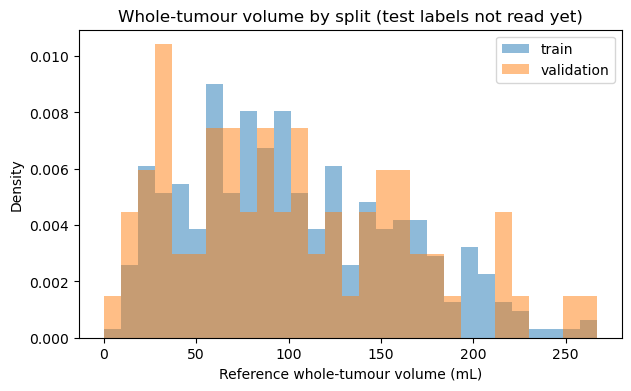

In [12]:
plt.figure(figsize=(7, 4))
bins = np.linspace(0, split_df["reference_ml"].max(), 30)
for split, colour in [("train", "tab:blue"), ("validation", "tab:orange")]:
    plt.hist(split_df.loc[split_df["split"] == split, "reference_ml"], bins=bins, density=True, alpha=0.5,
             color=colour, label=split)
plt.xlabel("Reference whole-tumour volume (mL)")
plt.ylabel("Density")
plt.title("Whole-tumour volume by split (test labels not read yet)")
plt.legend()
plt.show()

## Part C Preprocessing

### C.1 geometry of every case

In [13]:
def header_row(row):
    image_nii = nib.load(DATA_ROOT / row.image_relpath)
    label_nii = nib.load(DATA_ROOT / row.label_relpath)
    return {
        "case_id": row.case_id,
        "image_shape": str(image_nii.shape),
        "label_shape": str(label_nii.shape),
        "spacing": str(tuple(np.round(image_nii.header.get_zooms()[:3], 3).tolist())),
        "label_spacing": str(tuple(np.round(label_nii.header.get_zooms()[:3], 3).tolist())),
        "orientation": "".join(nib.aff2axcodes(image_nii.affine)),
        "label_orientation": "".join(nib.aff2axcodes(label_nii.affine)),
        "grid_match": image_nii.shape[:3] == label_nii.shape and bool(np.allclose(image_nii.affine, label_nii.affine)),
    }


with ThreadPoolExecutor(8) as pool:
    geometry = pd.DataFrame(pool.map(header_row, split_df.itertuples()))
for column in ["image_shape", "label_shape", "spacing", "label_spacing", "orientation", "label_orientation", "grid_match"]:
    print(column, geometry[column].value_counts().to_dict())

assert geometry["grid_match"].all()
assert geometry["spacing"].nunique() == 1
SPACING = np.array(nib.load(label_path(example_id)).header.get_zooms()[:3], dtype=float)
VOXEL_ML = float(np.prod(SPACING) / 1000)
print("Target grid = native grid:", geometry["image_shape"].iloc[0], "| spacing", SPACING, "mm | voxel", VOXEL_ML, "mL")

image_shape {'(240, 240, 155, 4)': 484}
label_shape {'(240, 240, 155)': 484}
spacing {'(1.0, 1.0, 1.0)': 484}
label_spacing {'(1.0, 1.0, 1.0)': 484}
orientation {'RAS': 484}
label_orientation {'RAS': 484}
grid_match {True: 484}
Target grid = native grid: (240, 240, 155, 4) | spacing [1. 1. 1.] mm | voxel 0.001 mL


### C.2 interpolation for images and labels

In [14]:
TARGET_SPACING = (1.5, 1.5, 1.5)
label_float = nib.Nifti1Image(example_label.astype(np.float32), example_label_affine)
resampled = {
    "Label, nearest (order 0)": resample_to_output(label_float, voxel_sizes=TARGET_SPACING, order=0),
    "Label, linear (order 1)": resample_to_output(label_float, voxel_sizes=TARGET_SPACING, order=1),
}
flair_resampled = resample_to_output(nib.Nifti1Image(example_volume[0], example_affine), voxel_sizes=TARGET_SPACING, order=1)
print("FLAIR, linear:", example_volume[0].shape, "->", flair_resampled.shape, "| zooms", flair_resampled.header.get_zooms())

new_voxel_ml = np.prod(TARGET_SPACING) / 1000
rows = [{
    "method": "Original 1 mm label",
    "shape": example_label.shape,
    "unique values": len(np.unique(example_label)),
    "first values": np.unique(example_label)[:5].tolist(),
    "invalid voxels": 0,
    "whole tumour (mL)": round((example_label > 0).sum() * VOXEL_ML, 2),
}]
for name, image in resampled.items():
    data = np.asarray(image.dataobj)
    values = np.unique(data)
    rows.append({
        "method": name,
        "shape": data.shape,
        "unique values": len(values),
        "first values": values[:5].round(3).tolist(),
        "invalid voxels": int((~np.isin(data, [0, 1, 2, 3])).sum()),
        "whole tumour (mL)": round((data > 0).sum() * new_voxel_ml, 2),
    })
pd.DataFrame(rows).set_index("method")

FLAIR, linear: (240, 240, 155) -> (161, 161, 104) | zooms (np.float32(1.5), np.float32(1.5), np.float32(1.5))


,shape,unique values,first values,invalid voxels,whole tumour (mL)
method,,,,,
Original 1 mm label,"(240, 240, 155)",4,"[0, 1, 2, 3]",0,111.72
"Label, nearest (order 0)","(161, 161, 104)",4,"[0.0, 1.0, 2.0, 3.0]",0,111.70
"Label, linear (order 1)","(161, 161, 104)",25,"[0.0, 0.125, 0.25, 0.375, 0.5]",6843,119.38


### C.3 normalisation, crop and cache

In [15]:
PATCH_SIZE = np.array([64, 64, 64])
CROP_MARGIN = 4


def normalize_channels(volume):
    normalized = np.zeros_like(volume)
    for channel in range(volume.shape[0]):
        brain = volume[channel] != 0
        values = volume[channel][brain]
        normalized[channel][brain] = (values - values.mean()) / values.std()
    return normalized


def crop_box(brain):
    shape = np.array(brain.shape)
    coords = np.argwhere(brain)
    low = coords.min(axis=0) - CROP_MARGIN
    high = coords.max(axis=0) + 1 + CROP_MARGIN
    size = np.minimum(np.maximum(high - low, PATCH_SIZE), shape)
    low = np.clip((low + high) // 2 - size // 2, 0, shape - size)
    return low, low + size


def preprocess_case(row):
    volume, affine = load_image(row.case_id)
    normalized = normalize_channels(volume)
    brain = (volume != 0).any(axis=0)
    low, high = crop_box(brain)
    window = tuple(slice(a, b) for a, b in zip(low, high))
    cropped = normalized[(slice(None),) + window].astype(np.float16)
    np.save(CACHE_DIR / f"{row.case_id}_image.npy", cropped)

    result = {"case_id": row.case_id, "split": row.split}
    result.update({f"shape_{axis}": size for axis, size in zip("xyz", brain.shape)})
    result.update({f"{axis}0": int(a) for axis, a in zip("xyz", low)})
    result.update({f"{axis}1": int(b) for axis, b in zip("xyz", high)})
    result["brain_voxels"] = int(brain.sum())
    result["channel_mask_agreement"] = float((volume != 0).all(axis=0).sum() / brain.sum())
    for channel in range(volume.shape[0]):
        inside = volume[channel] != 0
        stored = cropped[channel][inside[window]].astype(np.float32)
        result[f"raw_mean_{channel}"] = float(volume[channel][inside].mean())
        result[f"raw_std_{channel}"] = float(volume[channel][inside].std())
        result[f"all_voxel_mean_{channel}"] = float(volume[channel].mean())
        result[f"norm_mean_{channel}"] = float(stored.mean())
        result[f"norm_std_{channel}"] = float(stored.std())

    if row.split != "test":
        label, label_affine = load_label(row.case_id)
        assert np.allclose(affine, label_affine)
        cropped_label = label[window]
        np.save(CACHE_DIR / f"{row.case_id}_label.npy", cropped_label)
        tumour = np.argwhere(cropped_label > 0)
        rng = np.random.default_rng(SEED)
        if len(tumour) > 5000:
            tumour = tumour[rng.choice(len(tumour), 5000, replace=False)]
        np.save(CACHE_DIR / f"{row.case_id}_tumour.npy", tumour.astype(np.int16))
        result["tumour_voxels"] = int((label > 0).sum())
        result["label_inside_crop"] = bool((cropped_label > 0).sum() == (label > 0).sum())
        result["label_values"] = str(sorted(np.unique(cropped_label).tolist()))
    return result


CASES_FILE = CACHE_DIR / "cases.csv"
if not CASES_FILE.exists():
    CACHE_DIR.mkdir(exist_ok=True)
    started = time.time()
    with ThreadPoolExecutor(6) as pool:
        cases = pd.DataFrame(pool.map(preprocess_case, split_df.itertuples()))
    cases.to_csv(CASES_FILE, index=False)
    print(f"Cached {len(cases)} cases in {(time.time() - started) / 60:.1f} min")

cases = pd.read_csv(CASES_FILE)
assert list(cases["case_id"]) == list(split_df["case_id"])
development_cases = cases[cases["split"] != "test"]
assert development_cases["label_inside_crop"].astype(bool).all()
crop_sizes = cases[["x1", "y1", "z1"]].to_numpy() - cases[["x0", "y0", "z0"]].to_numpy()
print("Crop size min:", crop_sizes.min(axis=0), "| median:", np.median(crop_sizes, axis=0), "| max:", crop_sizes.max(axis=0))
print("Cached label values:", development_cases["label_values"].value_counts().to_dict())
print("Voxels where all four channels are non-zero / brain voxels: min", round(cases["channel_mask_agreement"].min(), 4),
      "| median", round(cases["channel_mask_agreement"].median(), 4), "| cases below 0.95:", int((cases["channel_mask_agreement"] < 0.95).sum()))
print("Cache size:", round(sum(path.stat().st_size for path in CACHE_DIR.glob("*.npy")) / 1e9, 2), "GB")

Cached 484 cases in 1.8 min
Crop size min: [130 152 127] | median: [146. 177. 146.] | max: [168 195 155]
Cached label values: {'[0, 1, 2, 3]': 399, '[0, 1, 2]': 12}
Voxels where all four channels are non-zero / brain voxels: min 0.4962 | median 1.0 | cases below 0.95: 15
Cache size: 16.12 GB


In [16]:
brain_fraction = cases["brain_voxels"] / (cases["shape_x"] * cases["shape_y"] * cases["shape_z"])
print("Brain voxels as a share of the full grid: mean", round(brain_fraction.mean(), 3))
rows = []
for channel, name in enumerate(MODALITIES):
    rows.append({
        "channel": name,
        "raw brain mean (case mean)": cases[f"raw_mean_{channel}"].mean(),
        "raw brain mean (between-case SD)": cases[f"raw_mean_{channel}"].std(),
        "raw mean incl. background": cases[f"all_voxel_mean_{channel}"].mean(),
        "normalised brain mean": cases[f"norm_mean_{channel}"].mean(),
        "normalised brain SD": cases[f"norm_std_{channel}"].mean(),
        "max |mean|": cases[f"norm_mean_{channel}"].abs().max(),
        "max |SD - 1|": (cases[f"norm_std_{channel}"] - 1).abs().max(),
    })
pd.DataFrame(rows).set_index("channel").round(4)

Brain voxels as a share of the full grid: mean 0.161


,raw brain mean (case mean),raw brain mean (between-case SD),raw mean incl. background,normalised brain mean,normalised brain SD,max |mean|,max |SD - 1|
channel,,,,,,,
FLAIR,460.9130,216.1672,73.7044,0.0,1.0,0.0000,0.0001
T1w,607.3136,300.1876,97.7214,0.0,1.0,0.0001,0.0001
t1gd,604.4161,317.4998,97.1921,-0.0,1.0,0.0000,0.0001
T2w,481.6059,202.2473,77.6804,0.0,1.0,0.0000,0.0002


### C.4 training-only augmentation

Mask values after: [0.0, 1.0] | tumour voxels before/after: 111724 111724
Brain/background layout unchanged (after flipping): True
FLAIR brain mean/SD before: 0.0 1.0 | after: 0.1 1.1


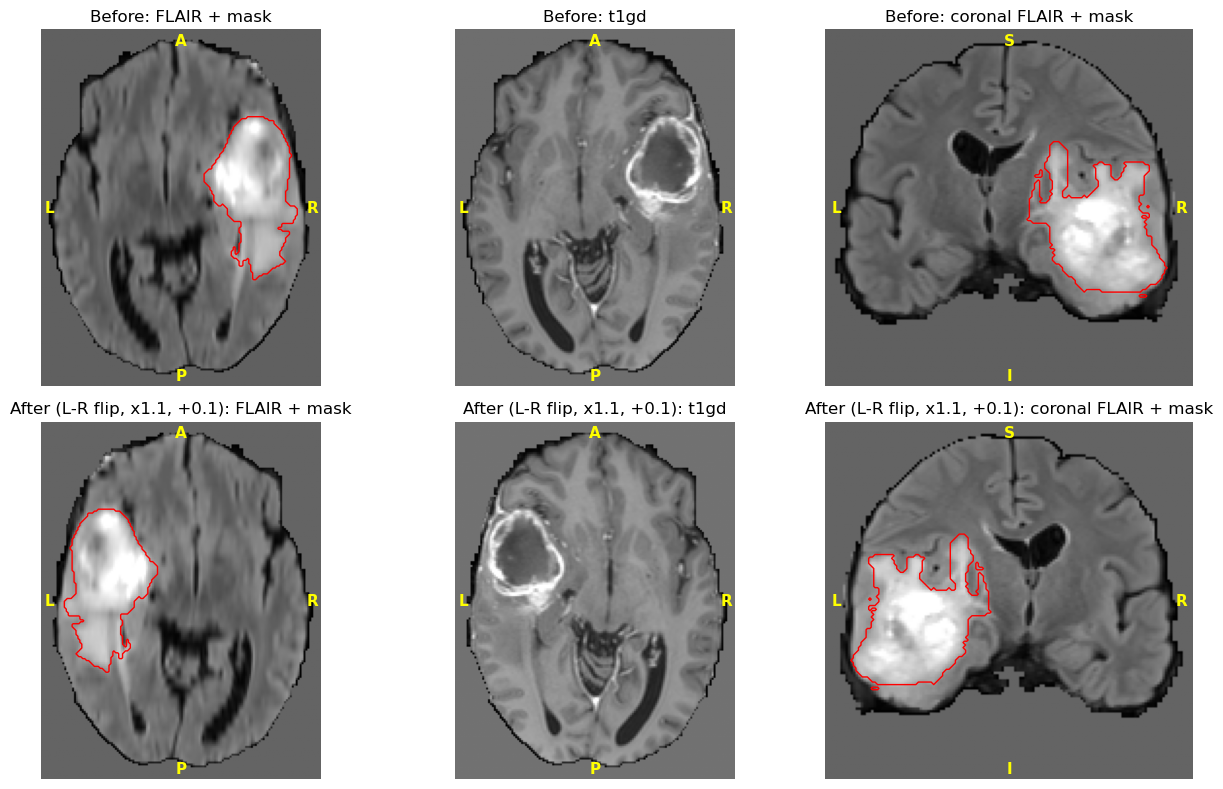

In [17]:
def apply_augmentation(image, mask, flip, scale, shift):
    if flip:
        image = image[:, ::-1]
        mask = mask[:, ::-1]
    brain = image != 0
    image = np.where(brain, image * scale + shift, 0).astype(np.float32)
    return np.ascontiguousarray(image), np.ascontiguousarray(mask)


def augment(image, mask, rng):
    flip = rng.random() < 0.5
    scale = rng.uniform(0.9, 1.1, size=(image.shape[0], 1, 1, 1))
    shift = rng.uniform(-0.1, 0.1, size=(image.shape[0], 1, 1, 1))
    return apply_augmentation(image, mask, flip, scale, shift)


example_image = np.load(CACHE_DIR / f"{example_id}_image.npy").astype(np.float32)
example_mask = (np.load(CACHE_DIR / f"{example_id}_label.npy") > 0).astype(np.float32)[None]
before_image, before_mask = example_image, example_mask
after_image, after_mask = apply_augmentation(example_image, example_mask, True,
                                             np.full((4, 1, 1, 1), 1.1), np.full((4, 1, 1, 1), 0.1))
print("Mask values after:", np.unique(after_mask).tolist(), "| tumour voxels before/after:", int(before_mask.sum()), int(after_mask.sum()))
print("Brain/background layout unchanged (after flipping):", bool(np.array_equal(after_image != 0, before_image[:, ::-1] != 0)))
print("FLAIR brain mean/SD before:", before_image[0][before_image[0] != 0].mean().round(3), before_image[0][before_image[0] != 0].std().round(3),
      "| after:", after_image[0][after_image[0] != 0].mean().round(3), after_image[0][after_image[0] != 0].std().round(3))

centre = np.round(np.argwhere(before_mask[0] > 0).mean(axis=0)).astype(int)
flipped_centre = centre.copy()
flipped_centre[0] = before_mask.shape[1] - 1 - centre[0]
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for row_number, (title, image, mask, point) in enumerate([("Before", before_image, before_mask, centre),
                                                         ("After (L-R flip, x1.1, +0.1)", after_image, after_mask, flipped_centre)]):
    show_plane(axes[row_number, 0], image[0], "Axial", point, SPACING, codes, contour=mask[0], vmax=4)
    axes[row_number, 0].set_title(f"{title}: FLAIR + mask")
    show_plane(axes[row_number, 1], image[2], "Axial", point, SPACING, codes, vmax=4)
    axes[row_number, 1].set_title(f"{title}: {MODALITIES[2]}")
    show_plane(axes[row_number, 2], image[0], "Coronal", point, SPACING, codes, contour=mask[0], vmax=4)
    axes[row_number, 2].set_title(f"{title}: coronal FLAIR + mask")
plt.tight_layout()
plt.show()

## Part D Patch-based volumetric training

### D.1 dataset and loader

In [18]:
BATCH_SIZE = 4
FOREGROUND_PROBABILITY = 0.5


class PatchDataset(Dataset):
    def __init__(self, table, sampler, n_samples, foreground_probability=FOREGROUND_PROBABILITY, augment=False, seed=SEED):
        self.case_ids = table["case_id"].tolist()
        self.sampler = sampler
        self.n_samples = n_samples
        self.foreground_probability = foreground_probability
        self.augment = augment
        self.rng = np.random.default_rng(seed)
        self.images = [np.load(CACHE_DIR / f"{case_id}_image.npy", mmap_mode="r") for case_id in self.case_ids]
        self.labels = [np.load(CACHE_DIR / f"{case_id}_label.npy", mmap_mode="r") for case_id in self.case_ids]
        self.tumour_voxels = [np.load(CACHE_DIR / f"{case_id}_tumour.npy") for case_id in self.case_ids]

    def __len__(self):
        return self.n_samples

    def patch_start(self, case, tumour_centred):
        shape = np.array(self.labels[case].shape)
        if tumour_centred and len(self.tumour_voxels[case]) > 0:
            centre = self.tumour_voxels[case][self.rng.integers(len(self.tumour_voxels[case]))]
            return np.clip(centre - PATCH_SIZE // 2, 0, shape - PATCH_SIZE)
        return np.array([self.rng.integers(0, size - patch + 1) for size, patch in zip(shape, PATCH_SIZE)])

    def extract(self, case, start):
        window = tuple(slice(int(a), int(a + p)) for a, p in zip(start, PATCH_SIZE))
        image = np.asarray(self.images[case][(slice(None),) + window], dtype=np.float32)
        mask = (np.asarray(self.labels[case][window]) > 0).astype(np.float32)[None]
        return image, mask

    def __getitem__(self, index):
        case = self.rng.integers(len(self.case_ids))
        tumour_centred = self.sampler == "tumour" and self.rng.random() < self.foreground_probability
        image, mask = self.extract(case, self.patch_start(case, tumour_centred))
        if self.augment:
            image, mask = augment(image, mask, self.rng)
        return torch.from_numpy(image), torch.from_numpy(mask)


train_table = split_df[split_df["split"] == "train"].reset_index(drop=True)
validation_table = split_df[split_df["split"] == "validation"].reset_index(drop=True)
test_table = split_df[split_df["split"] == "test"].reset_index(drop=True)

check_loader = DataLoader(PatchDataset(train_table, "uniform", n_samples=BATCH_SIZE, augment=True), batch_size=BATCH_SIZE, num_workers=0)
images, masks = next(iter(check_loader))
print("Image batch [B, C, D, H, W]:", tuple(images.shape), images.dtype, "| range:", round(float(images.min()), 2), "to", round(float(images.max()), 2))
print("Mask batch  [B, 1, D, H, W]:", tuple(masks.shape), masks.dtype, "| values:", torch.unique(masks).tolist())
print("Per-channel mean of brain voxels in batch:", [round(float(images[:, c][images[:, c] != 0].mean()), 3) for c in range(4)])
assert images.shape[1:] == (4, *PATCH_SIZE) and masks.shape[1:] == (1, *PATCH_SIZE)
assert set(torch.unique(masks).tolist()) <= {0.0, 1.0}

Image batch [B, C, D, H, W]: (4, 4, 64, 64, 64) torch.float32 | range: -5.64 to 12.52
Mask batch  [B, 1, D, H, W]: (4, 1, 64, 64, 64) torch.float32 | values: [0.0, 1.0]
Per-channel mean of brain voxels in batch: [0.333, 0.214, 0.276, 0.159]


In [19]:
def simulate_patches(table, patch, sampler, n_patches=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    labels = [np.load(CACHE_DIR / f"{case_id}_label.npy", mmap_mode="r") for case_id in table["case_id"]]
    tumours = [np.load(CACHE_DIR / f"{case_id}_tumour.npy") for case_id in table["case_id"]]
    size = np.array([patch] * 3)
    with_tumour, share = [], []
    for _ in range(n_patches):
        case = rng.integers(len(labels))
        shape = np.array(labels[case].shape)
        if sampler == "tumour" and rng.random() < FOREGROUND_PROBABILITY:
            start = np.clip(tumours[case][rng.integers(len(tumours[case]))] - size // 2, 0, shape - size)
        else:
            start = np.array([rng.integers(0, s - patch + 1) for s in shape])
        mask = labels[case][start[0]:start[0] + patch, start[1]:start[1] + patch, start[2]:start[2] + patch] > 0
        with_tumour.append(mask.any())
        share.append(mask.mean())
    return {"patch": patch, "sampler": sampler, "patches with tumour": np.mean(with_tumour), "tumour voxel share": np.mean(share)}


pd.DataFrame([simulate_patches(train_table, patch, sampler) for patch in [64, 96] for sampler in ["uniform", "tumour"]]).round(3)

,patch,sampler,patches with tumour,tumour voxel share
0,64,uniform,0.747,0.063
1,64,tumour,0.885,0.158
2,96,uniform,0.990,0.065
3,96,tumour,0.992,0.087


### D.2 3D U-Net

In [20]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.InstanceNorm3d(out_channels, affine=True),
            nn.LeakyReLU(0.01, inplace=True),
            nn.Conv3d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.InstanceNorm3d(out_channels, affine=True),
            nn.LeakyReLU(0.01, inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNet3D(nn.Module):
    def __init__(self, in_channels=4, out_channels=1, widths=(16, 32, 64, 128)):
        super().__init__()
        self.encoders = nn.ModuleList()
        channels = in_channels
        for width in widths:
            self.encoders.append(ConvBlock(channels, width))
            channels = width
        self.upsamplers = nn.ModuleList()
        self.decoders = nn.ModuleList()
        for width in reversed(widths[:-1]):
            self.upsamplers.append(nn.ConvTranspose3d(channels, width, kernel_size=2, stride=2))
            self.decoders.append(ConvBlock(2 * width, width))
            channels = width
        self.head = nn.Conv3d(channels, out_channels, kernel_size=1)

    def forward(self, x):
        skips = []
        for encoder in self.encoders[:-1]:
            x = encoder(x)
            skips.append(x)
            x = F.max_pool3d(x, 2)
        x = self.encoders[-1](x)
        for upsampler, decoder, skip in zip(self.upsamplers, self.decoders, reversed(skips)):
            x = decoder(torch.cat([upsampler(x), skip], dim=1))
        return self.head(x)


def autocast():
    return torch.autocast(device_type=DEVICE.type, dtype=torch.bfloat16, enabled=DEVICE.type != "cpu")


model = UNet3D().to(DEVICE)
with torch.no_grad(), autocast():
    output = model(images.to(DEVICE))
print("Input channels:", model.encoders[0].block[0].in_channels, "| output channels:", model.head.out_channels)
print("Parameters:", sum(parameter.numel() for parameter in model.parameters()))
print("Patch size:", tuple(PATCH_SIZE.tolist()), "| input", tuple(images.shape), "-> logits", tuple(output.shape))
assert output.shape == (BATCH_SIZE, 1, *PATCH_SIZE)

Input channels: 4 | output channels: 1
Parameters: 1402561
Patch size: (64, 64, 64) | input (4, 4, 64, 64, 64) -> logits (4, 1, 64, 64, 64)


### D.3 loss, metrics and sliding-window inference

In [21]:
THRESHOLD = 0.5


def dice_bce_loss(logits, target):
    bce = F.binary_cross_entropy_with_logits(logits, target)
    probabilities = torch.sigmoid(logits)
    intersection = (probabilities * target).sum(dim=(2, 3, 4))
    denominator = probabilities.sum(dim=(2, 3, 4)) + target.sum(dim=(2, 3, 4))
    dice = (2 * intersection + 1) / (denominator + 1)
    return bce + (1 - dice).mean()


def overlap_metrics(prediction, reference, voxel_ml=VOXEL_ML):
    tp = int(np.logical_and(prediction, reference).sum())
    fp = int(np.logical_and(prediction, ~reference).sum())
    fn = int(np.logical_and(~prediction, reference).sum())
    return {
        "dice": 2 * tp / max(2 * tp + fp + fn, 1),
        "iou": tp / max(tp + fp + fn, 1),
        "sensitivity": tp / max(tp + fn, 1),
        "fp_ml": fp * voxel_ml,
        "fn_ml": fn * voxel_ml,
        "pred_ml": (tp + fp) * voxel_ml,
        "ref_ml": (tp + fn) * voxel_ml,
    }


def window_starts(length, patch, overlap):
    stride = max(int(patch * (1 - overlap)), 1)
    count = int(np.ceil(max(length - patch, 0) / stride)) + 1
    return np.round(np.linspace(0, length - patch, count)).astype(int)


def gaussian_weight(patch_size, sigma_scale=1 / 8):
    profiles = [np.exp(-0.5 * ((np.arange(p) - (p - 1) / 2) / (p * sigma_scale)) ** 2) for p in patch_size]
    weight = profiles[0][:, None, None] * profiles[1][None, :, None] * profiles[2][None, None, :]
    return np.maximum(weight / weight.max(), 1e-4).astype(np.float32)


GAUSSIAN = gaussian_weight(PATCH_SIZE)


@torch.no_grad()
def sliding_window_probability(model, image, overlap=0.5, batch_size=8):
    model.eval()
    starts = list(itertools.product(*[window_starts(n, p, overlap) for n, p in zip(image.shape[1:], PATCH_SIZE)]))
    probability_sum = np.zeros(image.shape[1:], dtype=np.float32)
    weight_sum = np.zeros(image.shape[1:], dtype=np.float32)
    image = torch.from_numpy(np.asarray(image, dtype=np.float32))
    for first in range(0, len(starts), batch_size):
        windows = [tuple(slice(int(s), int(s + p)) for s, p in zip(start, PATCH_SIZE)) for start in starts[first:first + batch_size]]
        batch = torch.stack([image[(slice(None),) + window] for window in windows]).to(DEVICE)
        with autocast():
            logits = model(batch)
        probabilities = torch.sigmoid(logits.float())[:, 0].cpu().numpy()
        for window, probability in zip(windows, probabilities):
            probability_sum[window] += probability * GAUSSIAN
            weight_sum[window] += GAUSSIAN
    return probability_sum / weight_sum


def evaluate_validation(model, table, overlap=0.5):
    rows = []
    for case_id in table["case_id"]:
        image = np.load(CACHE_DIR / f"{case_id}_image.npy", mmap_mode="r")
        reference = np.load(CACHE_DIR / f"{case_id}_label.npy") > 0
        probability = sliding_window_probability(model, image, overlap)
        rows.append({"case_id": case_id, **overlap_metrics(probability >= THRESHOLD, reference)})
    return pd.DataFrame(rows)


started = time.time()
check = evaluate_validation(model, validation_table.head(2))
print(f"Untrained model on 2 validation volumes: {(time.time() - started) / 2:.1f} s per volume")
check.round(3)

Untrained model on 2 validation volumes: 2.1 s per volume


,case_id,dice,iou,sensitivity,fp_ml,fn_ml,pred_ml,ref_ml
0,BRATS_006,0.096,0.051,0.858,3471.997,30.867,3658.489,217.359
1,BRATS_019,0.083,0.044,0.920,3006.747,12.011,3144.080,149.344


### D.4 training setup

In [22]:
EPOCHS = 10
ITERATIONS_PER_EPOCH = 300
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
SAMPLERS = ["uniform", "tumour"]


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


MODEL_DIR.mkdir(exist_ok=True)
INITIAL_STATE_FILE = MODEL_DIR / "unet3d_initial.pt"
if not INITIAL_STATE_FILE.exists():
    set_seed(SEED)
    torch.save(UNet3D().state_dict(), INITIAL_STATE_FILE)
initial_state = torch.load(INITIAL_STATE_FILE)

validation_sampler = PatchDataset(validation_table, "tumour", n_samples=0, seed=SEED)
validation_patches = [(case, validation_sampler.patch_start(case, tumour_centred))
                      for case in range(len(validation_table)) for tumour_centred in [True, False]]
print("Loss: BCE + soft Dice | optimizer: Adam, lr", LEARNING_RATE, "weight decay", WEIGHT_DECAY, "cosine decay to 1e-5")
print("Budget:", EPOCHS, "epochs x", ITERATIONS_PER_EPOCH, "iterations x batch", BATCH_SIZE, "=",
      EPOCHS * ITERATIONS_PER_EPOCH * BATCH_SIZE, "patches | seed", SEED)
print("Fixed validation patches:", len(validation_patches), "(one tumour-centred and one random per case)")

Loss: BCE + soft Dice | optimizer: Adam, lr 0.001 weight decay 1e-05 cosine decay to 1e-5
Budget: 10 epochs x 300 iterations x batch 4 = 12000 patches | seed 42
Fixed validation patches: 146 (one tumour-centred and one random per case)


In [23]:
@torch.no_grad()
def validation_loss(model):
    model.eval()
    total = 0.0
    for first in range(0, len(validation_patches), 4):
        pairs = [validation_sampler.extract(case, start) for case, start in validation_patches[first:first + 4]]
        images = torch.from_numpy(np.stack([image for image, _ in pairs])).to(DEVICE)
        masks = torch.from_numpy(np.stack([mask for _, mask in pairs])).to(DEVICE)
        with autocast():
            logits = model(images)
        total += dice_bce_loss(logits.float(), masks).item() * len(pairs)
    return total / len(validation_patches)


def train_model(sampler):
    set_seed(SEED)
    model = UNet3D().to(DEVICE)
    model.load_state_dict(initial_state)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS * ITERATIONS_PER_EPOCH, eta_min=1e-5)
    dataset = PatchDataset(train_table, sampler, n_samples=ITERATIONS_PER_EPOCH * BATCH_SIZE, augment=True, seed=SEED)
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

    history = []
    best_dice, best_epoch, best_state = -1.0, 0, None
    for epoch in range(1, EPOCHS + 1):
        started = time.time()
        model.train()
        losses, with_tumour, tumour_fraction = [], [], []
        for images, masks in loader:
            images, masks = images.to(DEVICE), masks.to(DEVICE)
            optimizer.zero_grad()
            with autocast():
                logits = model(images)
            loss = dice_bce_loss(logits.float(), masks)
            loss.backward()
            optimizer.step()
            scheduler.step()
            losses.append(loss.item())
            with_tumour.extend((masks.sum(dim=(1, 2, 3, 4)) > 0).cpu().tolist())
            tumour_fraction.extend(masks.mean(dim=(1, 2, 3, 4)).cpu().tolist())
        train_seconds = time.time() - started
        val_loss = validation_loss(model)
        val_metrics = evaluate_validation(model, validation_table)
        record = {
            "sampler": sampler,
            "epoch": epoch,
            "train_loss": float(np.mean(losses)),
            "val_loss": val_loss,
            "val_dice": val_metrics["dice"].mean(),
            "val_sensitivity": val_metrics["sensitivity"].mean(),
            "val_fp_ml": val_metrics["fp_ml"].mean(),
            "patches_with_tumour": float(np.mean(with_tumour)),
            "tumour_voxel_fraction": float(np.mean(tumour_fraction)),
            "learning_rate": scheduler.get_last_lr()[0],
            "train_seconds": train_seconds,
            "epoch_seconds": time.time() - started,
        }
        history.append(record)
        print(f"{sampler} epoch {epoch}: train={record['train_loss']:.4f}, val={val_loss:.4f}, "
              f"val Dice={record['val_dice']:.4f}, patches with tumour={record['patches_with_tumour']:.2f}, "
              f"{record['epoch_seconds'] / 60:.1f} min", flush=True)
        if record["val_dice"] > best_dice:
            best_dice, best_epoch = record["val_dice"], epoch
            best_state = copy.deepcopy(model.state_dict())
    history = pd.DataFrame(history)
    history["best_epoch"] = best_epoch
    return best_state, model.state_dict(), history

In [24]:
for sampler in SAMPLERS:
    model_file = MODEL_DIR / f"unet3d_{sampler}_best.pt"
    if model_file.exists():
        print(model_file.name, "is already trained")
        continue
    best_state, last_state, history = train_model(sampler)
    torch.save(best_state, model_file)
    torch.save(last_state, MODEL_DIR / f"unet3d_{sampler}_last.pt")
    history.to_csv(MODEL_DIR / f"unet3d_{sampler}_history.csv", index=False)

histories = pd.concat([pd.read_csv(MODEL_DIR / f"unet3d_{sampler}_history.csv") for sampler in SAMPLERS], ignore_index=True)
histories[["sampler", "epoch", "train_loss", "val_loss", "val_dice", "val_sensitivity", "val_fp_ml",
           "patches_with_tumour", "learning_rate", "epoch_seconds"]].round(4)

unet3d_uniform_best.pt is already trained
unet3d_tumour_best.pt is already trained


,sampler,epoch,train_loss,val_loss,val_dice,val_sensitivity,val_fp_ml,patches_with_tumour,learning_rate,epoch_seconds
0,uniform,1,1.1100,0.7282,0.7042,0.7080,17.7891,0.7458,0.0010,390.6757
1,uniform,2,0.7434,0.5555,0.7659,0.7620,13.2512,0.7592,0.0009,372.1519
2,uniform,3,0.6340,0.4904,0.7782,0.8501,22.4029,0.7458,0.0008,366.3507
3,uniform,4,0.5951,0.4763,0.7908,0.8938,25.6571,0.7358,0.0007,378.4366
4,uniform,5,0.5664,0.4557,0.8121,0.8605,18.3322,0.7692,0.0005,402.8975
5,uniform,6,0.5489,0.4579,0.7328,0.9126,42.4042,0.7567,0.0004,383.8144
6,uniform,7,0.5682,0.4229,0.8451,0.9006,19.0131,0.7292,0.0002,399.1919
7,uniform,8,0.5353,0.4147,0.8439,0.8828,17.0340,0.7492,0.0001,401.7697
8,uniform,9,0.5337,0.4155,0.8563,0.8775,13.3854,0.7417,0.0000,403.3907
9,uniform,10,0.5297,0.4158,0.8556,0.8609,11.4138,0.7492,0.0000,402.2868


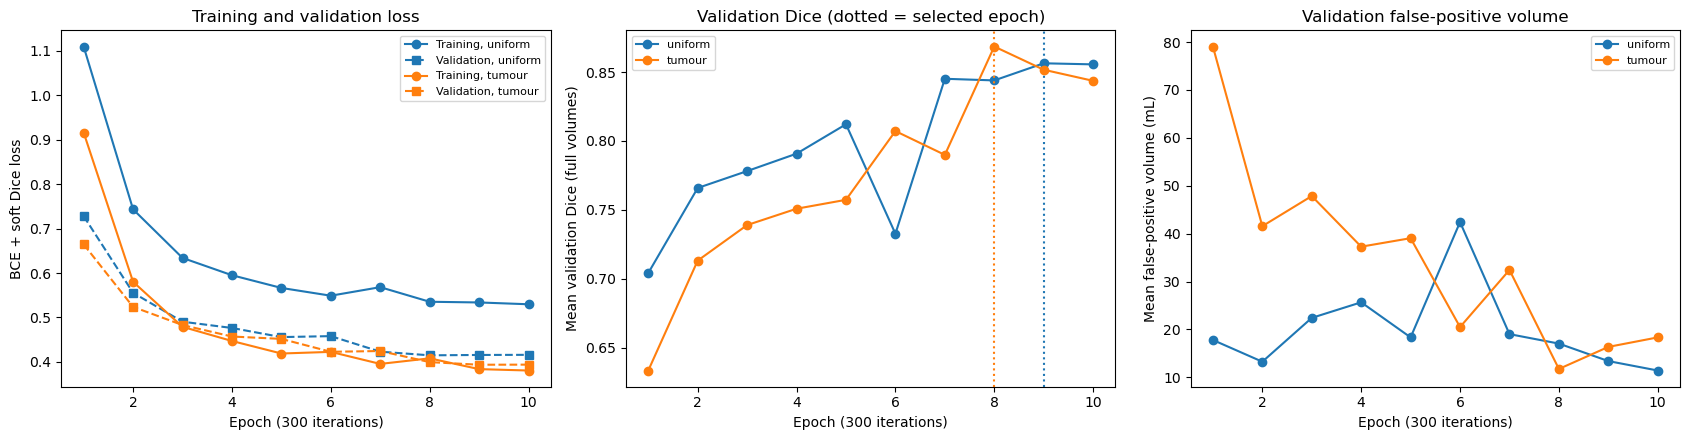

In [25]:
colours = {"uniform": "tab:blue", "tumour": "tab:orange"}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for sampler in SAMPLERS:
    history = histories[histories["sampler"] == sampler]
    colour = colours[sampler]
    axes[0].plot(history["epoch"], history["train_loss"], "o-", color=colour, label=f"Training, {sampler}")
    axes[0].plot(history["epoch"], history["val_loss"], "s--", color=colour, label=f"Validation, {sampler}")
    axes[1].plot(history["epoch"], history["val_dice"], "o-", color=colour, label=sampler)
    axes[1].axvline(history["best_epoch"].iloc[0], color=colour, linestyle=":")
    axes[2].plot(history["epoch"], history["val_fp_ml"], "o-", color=colour, label=sampler)
axes[0].set_ylabel("BCE + soft Dice loss")
axes[0].set_title("Training and validation loss")
axes[1].set_ylabel("Mean validation Dice (full volumes)")
axes[1].set_title("Validation Dice (dotted = selected epoch)")
axes[2].set_ylabel("Mean false-positive volume (mL)")
axes[2].set_title("Validation false-positive volume")
for ax in axes:
    ax.set_xlabel(f"Epoch ({ITERATIONS_PER_EPOCH} iterations)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Part E Controlled sampling comparison

In [26]:
def load_model(name):
    model = UNet3D().to(DEVICE)
    model.load_state_dict(torch.load(MODEL_DIR / f"unet3d_{name}.pt", map_location=DEVICE))
    model.eval()
    return model


validation_results = {sampler: evaluate_validation(load_model(f"{sampler}_best"), validation_table) for sampler in SAMPLERS}

rows = []
for sampler in SAMPLERS:
    result = validation_results[sampler]
    history = histories[histories["sampler"] == sampler]
    rows.append({
        "sampler": sampler,
        "selected epoch": history["best_epoch"].iloc[0],
        "patches with tumour": history["patches_with_tumour"].mean(),
        "tumour share of patch voxels": history["tumour_voxel_fraction"].mean(),
        "val Dice mean": result["dice"].mean(),
        "val Dice SD": result["dice"].std(),
        "val Dice median": result["dice"].median(),
        "sensitivity mean": result["sensitivity"].mean(),
        "FP volume mean (mL)": result["fp_ml"].mean(),
        "FP volume median (mL)": result["fp_ml"].median(),
        "FN volume mean (mL)": result["fn_ml"].mean(),
        "volume bias (mL)": (result["pred_ml"] - result["ref_ml"]).mean(),
    })
sampling_comparison = pd.DataFrame(rows).set_index("sampler")
sampling_comparison.round(3).T

sampler,uniform,tumour
selected epoch,9.000,8.000
patches with tumour,0.748,0.877
tumour share of patch voxels,0.066,0.153
val Dice mean,0.856,0.868
val Dice SD,0.086,0.083
val Dice median,0.888,0.898
sensitivity mean,0.878,0.883
FP volume mean (mL),13.385,11.740
FP volume median (mL),9.606,8.424
FN volume mean (mL),11.633,10.465


In [27]:
paired = validation_results["uniform"][["case_id", "ref_ml", "dice", "sensitivity", "fp_ml"]].merge(
    validation_results["tumour"][["case_id", "dice", "sensitivity", "fp_ml"]], on="case_id", suffixes=("_uniform", "_tumour"))
paired["size"] = pd.qcut(paired["ref_ml"], 3, labels=["small", "medium", "large"])
print("Cases where tumour-aware Dice is higher:", int((paired["dice_tumour"] > paired["dice_uniform"]).sum()), "of", len(paired))
print("Wilcoxon signed-rank p (Dice):", round(wilcoxon(paired["dice_tumour"], paired["dice_uniform"]).pvalue, 4))
print("Wilcoxon signed-rank p (FP volume):", round(wilcoxon(paired["fp_ml_tumour"], paired["fp_ml_uniform"]).pvalue, 4))
paired.groupby("size", observed=True).agg(
    cases=("case_id", "count"), reference_ml=("ref_ml", "median"),
    dice_uniform=("dice_uniform", "mean"), dice_tumour=("dice_tumour", "mean"),
    sensitivity_uniform=("sensitivity_uniform", "mean"), sensitivity_tumour=("sensitivity_tumour", "mean"),
    fp_ml_uniform=("fp_ml_uniform", "mean"), fp_ml_tumour=("fp_ml_tumour", "mean")).round(3)

Cases where tumour-aware Dice is higher: 50 of 73
Wilcoxon signed-rank p (Dice): 0.0001
Wilcoxon signed-rank p (FP volume): 0.0012


,cases,reference_ml,dice_uniform,dice_tumour,sensitivity_uniform,sensitivity_tumour,fp_ml_uniform,fp_ml_tumour
size,,,,,,,,
small,24,32.176,0.798,0.813,0.862,0.859,11.331,9.312
medium,24,90.104,0.887,0.891,0.891,0.891,10.015,9.190
large,25,165.326,0.883,0.899,0.879,0.899,18.593,16.520


In [28]:
selected_sampler = sampling_comparison["val Dice mean"].idxmax()
print("Selected configuration (highest mean validation Dice):", selected_sampler,
      "| epoch", int(sampling_comparison.loc[selected_sampler, "selected epoch"]))
final_model = load_model(f"{selected_sampler}_best")

Selected configuration (highest mean validation Dice): tumour | epoch 8


## Part F Full-volume reconstruction and test evaluation

### F.1 sliding-window inference

In [29]:
OVERLAP = 0.5
case_info = cases.set_index("case_id")


def predict_full_volume(model, case_id, overlap=OVERLAP, zero_channel=None):
    row = case_info.loc[case_id]
    image = np.load(CACHE_DIR / f"{case_id}_image.npy")
    if zero_channel is not None:
        image = image.copy()
        image[zero_channel] = 0
    probability = np.zeros((row.shape_x, row.shape_y, row.shape_z), dtype=np.float32)
    window = (slice(row.x0, row.x1), slice(row.y0, row.y1), slice(row.z0, row.z1))
    probability[window] = sliding_window_probability(model, image, overlap)
    return probability


stride = (PATCH_SIZE * (1 - OVERLAP)).astype(int)
example_crop = tuple(int(case_info.loc[test_table["case_id"][0], f"{a}1"] - case_info.loc[test_table["case_id"][0], f"{a}0"]) for a in "xyz")
example_starts = [window_starts(n, p, OVERLAP) for n, p in zip(example_crop, PATCH_SIZE)]
coverage = np.zeros(example_crop, dtype=np.int16)
for start in itertools.product(*example_starts):
    coverage[tuple(slice(int(s), int(s + p)) for s, p in zip(start, PATCH_SIZE))] += 1
print("Patch:", tuple(PATCH_SIZE.tolist()), "| nominal stride:", tuple(stride.tolist()), "| overlap:", OVERLAP)
print("Blending: Gaussian-weighted mean of sigmoid probabilities (sigma = patch/8), then threshold", THRESHOLD)
print("Example crop", example_crop, "-> window starts", [s.tolist() for s in example_starts],
      "| windows:", int(np.prod([len(s) for s in example_starts])), "| windows per voxel: min", coverage.min(), "max", coverage.max())

Patch: (64, 64, 64) | nominal stride: (32, 32, 32) | overlap: 0.5
Blending: Gaussian-weighted mean of sigmoid probabilities (sigma = patch/8), then threshold 0.5
Example crop (150, 184, 154) -> window starts [[0, 29, 57, 86], [0, 30, 60, 90, 120], [0, 30, 60, 90]] | windows: 80 | windows per voxel: min 1 max 27


### F.2 test metrics

In [30]:
def surface_voxels(mask):
    return mask & ~ndimage.binary_erosion(mask)


def hd95(prediction, reference, spacing=SPACING):
    if not prediction.any() or not reference.any():
        return np.nan
    coords = np.argwhere(prediction | reference)
    low = np.maximum(coords.min(axis=0) - 2, 0)
    high = coords.max(axis=0) + 3
    window = tuple(slice(a, b) for a, b in zip(low, high))
    prediction, reference = prediction[window], reference[window]
    prediction_surface, reference_surface = surface_voxels(prediction), surface_voxels(reference)
    to_reference = ndimage.distance_transform_edt(~reference_surface, sampling=spacing)[prediction_surface]
    to_prediction = ndimage.distance_transform_edt(~prediction_surface, sampling=spacing)[reference_surface]
    return float(max(np.percentile(to_reference, 95), np.percentile(to_prediction, 95)))


def evaluate_prediction(case_id, prediction, reference):
    metrics = overlap_metrics(prediction, reference)
    metrics["hd95_mm"] = hd95(prediction, reference)
    metrics["empty_prediction"] = not prediction.any()
    return {"case_id": case_id, **metrics}


def summarize(results):
    columns = ["dice", "iou", "sensitivity", "hd95_mm"]
    summary = results[columns].agg(["mean", "std", "median"]).T
    summary["cases with value"] = results[columns].count()
    summary["empty predictions"] = int(results["empty_prediction"].sum())
    return summary


test_references = {}
test_probabilities = {}
rows = []
started = time.time()
for case_id in test_table["case_id"]:
    reference, _ = load_label(case_id)
    test_references[case_id] = reference > 0
    test_probabilities[case_id] = predict_full_volume(final_model, case_id).astype(np.float16)
    rows.append(evaluate_prediction(case_id, test_probabilities[case_id] >= THRESHOLD, test_references[case_id]))
test_results = pd.DataFrame(rows)
print(f"Test inference + metrics: {(time.time() - started) / len(test_table):.1f} s per case")
summarize(test_results).round(3)

Test inference + metrics: 2.4 s per case


,mean,std,median,cases with value,empty predictions
dice,0.886,0.073,0.901,73,0
iou,0.801,0.106,0.820,73,0
sensitivity,0.881,0.080,0.895,73,0
hd95_mm,13.479,16.602,6.782,73,0


In [31]:
test_results["abs_volume_error_ml"] = (test_results["pred_ml"] - test_results["ref_ml"]).abs()
test_results["volume_error_pct"] = 100 * (test_results["pred_ml"] - test_results["ref_ml"]) / test_results["ref_ml"]
print("Volume per voxel:", VOXEL_ML * 1000, "mm3 =", VOXEL_ML, "mL")
print("Mean absolute volume error:", round(test_results["abs_volume_error_ml"].mean(), 2), "mL | median:",
      round(test_results["abs_volume_error_ml"].median(), 2), "mL")
print("Mean absolute percentage error:", round(test_results["volume_error_pct"].abs().mean(), 1), "% | median signed:",
      round(test_results["volume_error_pct"].median(), 1), "%")
test_results[["case_id", "ref_ml", "pred_ml", "abs_volume_error_ml", "volume_error_pct", "dice", "hd95_mm"]].round(2)

Volume per voxel: 1.0 mm3 = 0.001 mL
Mean absolute volume error: 12.08 mL | median: 8.26 mL
Mean absolute percentage error: 14.1 % | median signed: -4.3 %


,case_id,ref_ml,pred_ml,abs_volume_error_ml,volume_error_pct,dice,hd95_mm
0,BRATS_002,63.06,74.54,11.48,18.21,0.90,4.00
1,BRATS_012,21.61,21.06,0.55,-2.56,0.91,9.85
2,BRATS_016,82.73,91.95,9.22,11.14,0.90,6.78
3,BRATS_033,114.02,114.04,0.02,0.02,0.95,2.24
4,BRATS_039,37.01,26.65,10.36,-27.99,0.83,5.74
5,BRATS_050,76.24,68.71,7.53,-9.87,0.93,4.58
6,BRATS_059,99.57,91.31,8.26,-8.30,0.94,3.16
7,BRATS_065,166.09,178.19,12.10,7.29,0.86,8.06
8,BRATS_067,55.28,52.65,2.63,-4.76,0.93,9.90
9,BRATS_078,85.08,168.34,83.26,97.85,0.58,15.30


In [32]:
split_df.loc[split_df["split"] == "test", "reference_ml"] = split_df.loc[split_df["split"] == "test", "case_id"].map(test_results.set_index("case_id")["ref_ml"])
volume_summary(split_df)

,cases,labels read,mean (mL),SD,median,Q1,Q3,min,max
split,,,,,,,,,
train,338,338,103.0,57.0,95.5,60.0,143.9,8.5,265.3
validation,73,73,100.8,63.0,91.6,51.9,148.1,7.3,266.9
test,73,73,107.4,66.3,89.1,54.4,157.7,10.1,318.3


### F.3 connected-component postprocessing

In [33]:
def component_sizes(mask):
    components, count = ndimage.label(mask, structure=np.ones((3, 3, 3)))
    return np.bincount(components.ravel())[1:] * VOXEL_ML


rows = []
for case_id in train_table["case_id"]:
    sizes = component_sizes(np.load(CACHE_DIR / f"{case_id}_label.npy") > 0)
    rows.append({"case_id": case_id, "components": len(sizes), "largest_ml": sizes.max(), "sizes": sizes})
train_components = pd.DataFrame(rows)
all_sizes = np.concatenate(train_components["sizes"].to_numpy())
total_tumour = all_sizes.sum()
print("Training references: components per case median", int(train_components["components"].median()),
      "| cases with more than one component:", int((train_components["components"] > 1).sum()), "of", len(train_components))
rows = []
for min_ml in [0.01, 0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 5.0, 10.0]:
    lost = sum(sizes[(sizes < min_ml) & (sizes < sizes.max())].sum() for sizes in train_components["sizes"])
    rows.append({"min component (mL)": min_ml, "share of tumour volume removed": lost / total_tumour,
                 "components removed": int(sum(((sizes < min_ml) & (sizes < sizes.max())).sum() for sizes in train_components["sizes"]))})
component_candidates = pd.DataFrame(rows)
MIN_COMPONENT_ML = float(component_candidates.loc[component_candidates["share of tumour volume removed"] < 0.001, "min component (mL)"].max())
print("Largest threshold removing < 0.1% of training tumour volume:", MIN_COMPONENT_ML, "mL")
component_candidates.round(4)

Training references: components per case median 4 | cases with more than one component: 285 of 338
Largest threshold removing < 0.1% of training tumour volume: 0.5 mL


,min component (mL),share of tumour volume removed,components removed
0,0.01,0.0001,1415
1,0.05,0.0002,1631
2,0.10,0.0003,1674
3,0.25,0.0005,1713
4,0.50,0.0007,1730
5,1.00,0.0011,1754
6,2.00,0.0018,1770
7,5.00,0.0034,1788
8,10.00,0.0051,1797


In [34]:
def remove_small_components(prediction, min_ml=MIN_COMPONENT_ML):
    components, count = ndimage.label(prediction, structure=np.ones((3, 3, 3)))
    if count == 0:
        return prediction
    sizes = np.bincount(components.ravel())[1:] * VOXEL_ML
    keep = sizes >= min_ml
    keep[sizes.argmax()] = True
    return np.isin(components, np.flatnonzero(keep) + 1)


rows = []
for case_id in validation_table["case_id"]:
    image = np.load(CACHE_DIR / f"{case_id}_image.npy")
    reference = np.load(CACHE_DIR / f"{case_id}_label.npy") > 0
    prediction = sliding_window_probability(final_model, image, OVERLAP) >= THRESHOLD
    for rule, mask in [("before", prediction), ("after", remove_small_components(prediction))]:
        rows.append({"rule": rule, **evaluate_prediction(case_id, mask, reference)})
validation_postprocessing = pd.DataFrame(rows)
postprocessing_validation = validation_postprocessing.groupby("rule", sort=False).agg(
    dice_mean=("dice", "mean"), hd95_mean=("hd95_mm", "mean"), hd95_median=("hd95_mm", "median"),
    fp_ml_mean=("fp_ml", "mean"), sensitivity=("sensitivity", "mean"))
KEEP_POSTPROCESSING = bool(postprocessing_validation.loc["after", "dice_mean"] >= postprocessing_validation.loc["before", "dice_mean"]
                           and postprocessing_validation.loc["after", "hd95_mean"] <= postprocessing_validation.loc["before", "hd95_mean"])
print("Rule: keep the largest component and every 26-connected component of at least", MIN_COMPONENT_ML, "mL")
print("Keep the rule (decided on validation only):", KEEP_POSTPROCESSING)
postprocessing_validation.round(3)

Rule: keep the largest component and every 26-connected component of at least 0.5 mL
Keep the rule (decided on validation only): True


,dice_mean,hd95_mean,hd95_median,fp_ml_mean,sensitivity
rule,,,,,
before,0.868,24.272,8.485,11.740,0.883
after,0.871,20.514,7.280,11.449,0.883


In [35]:
rows = []
for case_id in test_table["case_id"]:
    prediction = remove_small_components(test_probabilities[case_id] >= THRESHOLD)
    rows.append(evaluate_prediction(case_id, prediction, test_references[case_id]))
test_results_post = pd.DataFrame(rows)
test_results_post["abs_volume_error_ml"] = (test_results_post["pred_ml"] - test_results_post["ref_ml"]).abs()
test_results_post["volume_error_pct"] = 100 * (test_results_post["pred_ml"] - test_results_post["ref_ml"]) / test_results_post["ref_ml"]

comparison = pd.concat({"before": summarize(test_results), "after": summarize(test_results_post)})
for name, results in [("before", test_results), ("after", test_results_post)]:
    print(f"{name}: mean abs volume error {results['abs_volume_error_ml'].mean():.2f} mL, mean FP volume {results['fp_ml'].mean():.2f} mL")
print("Cases changed by the rule:", int((test_results_post["pred_ml"] != test_results["pred_ml"]).sum()))
comparison.round(3)

before: mean abs volume error 12.08 mL, mean FP volume 9.66 mL
after: mean abs volume error 12.08 mL, mean FP volume 9.44 mL
Cases changed by the rule: 65


mean     std  median  cases with value  empty predictions
before dice          0.886   0.073   0.901                73                  0
       iou           0.801   0.106   0.820                73                  0
       sensitivity   0.881   0.080   0.895                73                  0
       hd95_mm      13.479  16.602   6.782                73                  0
after  dice          0.888   0.070   0.902                73                  0
       iou           0.804   0.103   0.822                73                  0
       sensitivity   0.881   0.080   0.895                73                  0
       hd95_mm      12.335  15.994   5.831                73                  0

In [36]:
final_results = test_results_post if KEEP_POSTPROCESSING else test_results


def final_prediction(case_id):
    prediction = test_probabilities[case_id] >= THRESHOLD
    return remove_small_components(prediction) if KEEP_POSTPROCESSING else prediction


print("Final pipeline:", selected_sampler, "sampler,", "with" if KEEP_POSTPROCESSING else "without", "postprocessing")
summarize(final_results).round(3)

Final pipeline: tumour sampler, with postprocessing


,mean,std,median,cases with value,empty predictions
dice,0.888,0.070,0.902,73,0
iou,0.804,0.103,0.822,73,0
sensitivity,0.881,0.080,0.895,73,0
hd95_mm,12.335,15.994,5.831,73,0


## Part G Three-plane error analysis

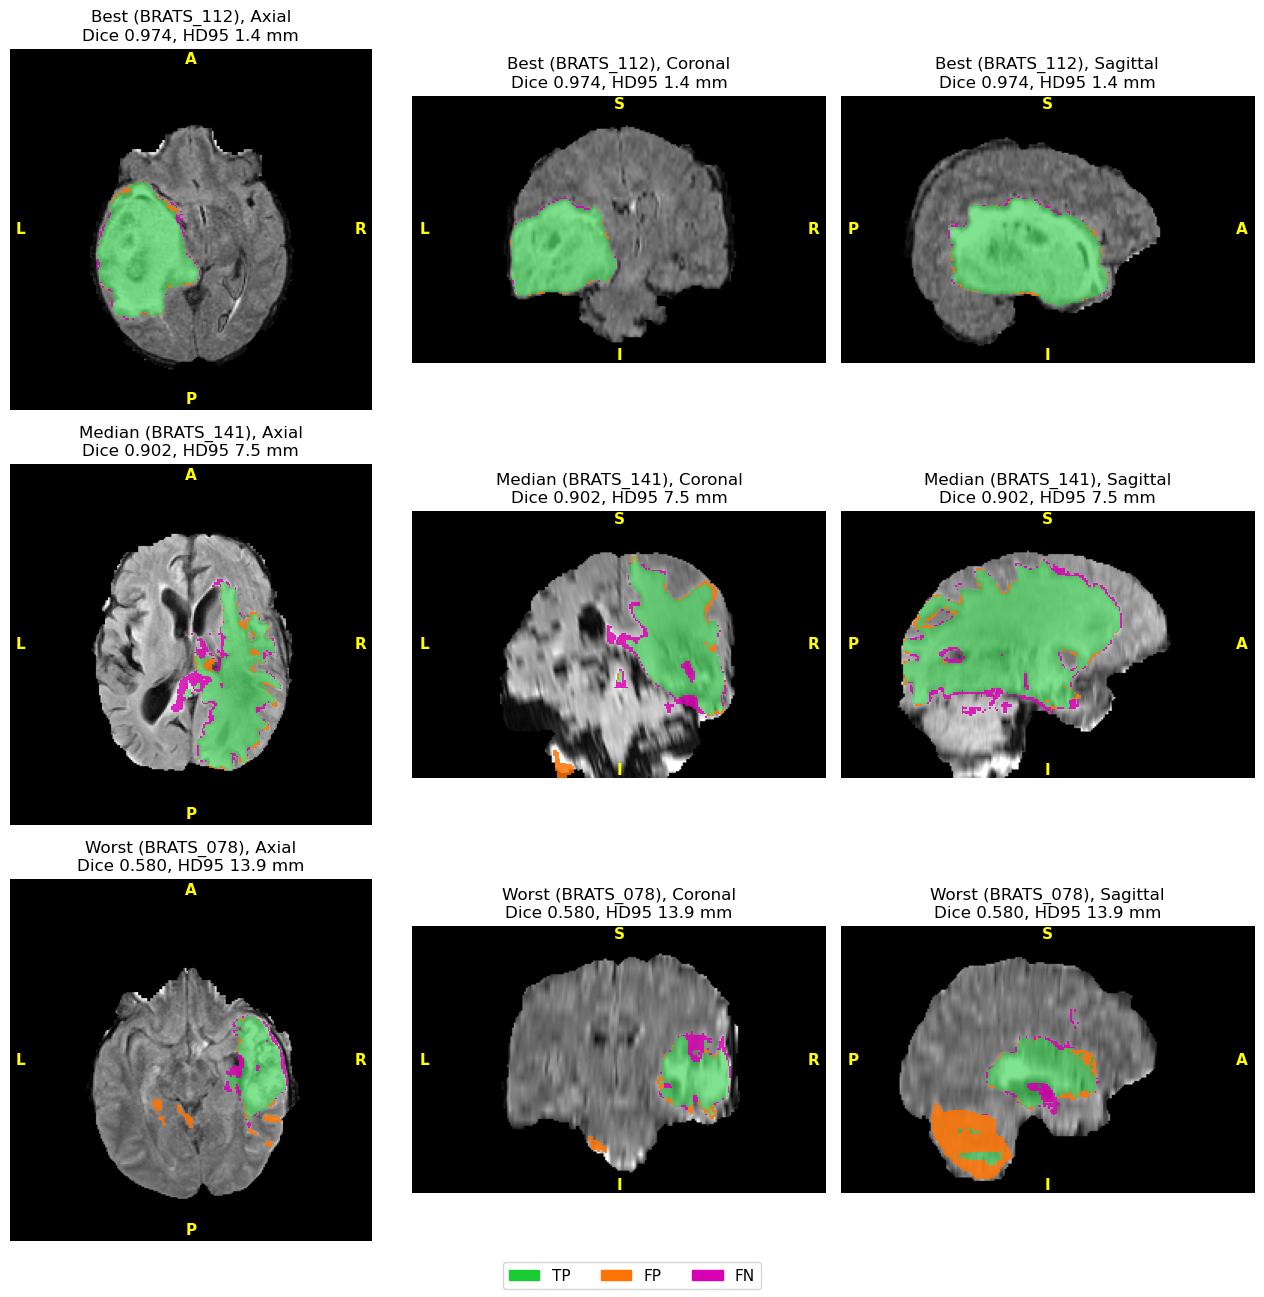

,case_id,dice,iou,sensitivity,hd95_mm,ref_ml,pred_ml,fp_ml,fn_ml,volume_error_pct
case,,,,,,,,,,
Best,BRATS_112,0.974,0.949,0.973,1.414,169.185,168.782,4.178,4.581,-0.238
Median,BRATS_141,0.902,0.822,0.866,7.550,268.741,246.832,14.207,36.116,-8.152
Worst,BRATS_078,0.580,0.409,0.862,13.905,85.083,167.488,94.180,11.775,96.852


In [37]:
ERROR_COLOURS = {"TP": (0.1, 0.8, 0.2), "FP": (1.0, 0.45, 0.0), "FN": (0.85, 0.0, 0.7)}


def error_overlay(prediction, reference):
    overlay = np.zeros(prediction.shape + (4,), dtype=np.float32)
    overlay[prediction & reference] = (*ERROR_COLOURS["TP"], 0.55)
    overlay[prediction & ~reference] = (*ERROR_COLOURS["FP"], 0.85)
    overlay[~prediction & reference] = (*ERROR_COLOURS["FN"], 0.85)
    return overlay


ranked = final_results.sort_values("dice").reset_index(drop=True)
chosen = {"Best": ranked.iloc[-1], "Median": ranked.iloc[len(ranked) // 2], "Worst": ranked.iloc[0]}

fig, axes = plt.subplots(3, 3, figsize=(13, 13))
for row_number, (name, result) in enumerate(chosen.items()):
    case_id = result["case_id"]
    flair = load_image(case_id)[0][0]
    reference = test_references[case_id]
    prediction = final_prediction(case_id)
    centre = np.round(np.argwhere(reference).mean(axis=0)).astype(int)
    overlay = error_overlay(prediction, reference)
    vmax = np.percentile(flair[flair > 0], 99.5)
    for column, plane in enumerate(PLANES):
        show_plane(axes[row_number, column], flair, plane, centre, SPACING, codes, overlay=overlay, vmax=vmax)
        axes[row_number, column].set_title(f"{name} ({case_id}), {plane}\nDice {result['dice']:.3f}, HD95 {result['hd95_mm']:.1f} mm")
fig.legend(handles=[Patch(color=colour, label=label) for label, colour in ERROR_COLOURS.items()],
           loc="lower center", ncol=3, fontsize=11)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

pd.DataFrame([{"case": name, "case_id": r["case_id"], "dice": r["dice"], "iou": r["iou"], "sensitivity": r["sensitivity"],
               "hd95_mm": r["hd95_mm"], "ref_ml": r["ref_ml"], "pred_ml": r["pred_ml"], "fp_ml": r["fp_ml"], "fn_ml": r["fn_ml"],
               "volume_error_pct": r["volume_error_pct"]} for name, r in chosen.items()]).set_index("case").round(3)

In [38]:
rows = []
component_rows = []
for case_id in test_table["case_id"]:
    reference = test_references[case_id]
    prediction = final_prediction(case_id)
    distance = ndimage.distance_transform_edt(~surface_voxels(reference), sampling=SPACING)
    errors = prediction ^ reference
    rows.append({
        "case_id": case_id,
        "error_voxels": int(errors.sum()),
        "errors_within_2mm": float((distance[errors] <= 2).mean()) if errors.any() else np.nan,
        "fp_within_2mm": float((distance[prediction & ~reference] <= 2).mean()) if (prediction & ~reference).any() else np.nan,
        "fn_within_2mm": float((distance[~prediction & reference] <= 2).mean()) if (~prediction & reference).any() else np.nan,
    })
    components, count = ndimage.label(reference, structure=np.ones((3, 3, 3)))
    for index in range(1, count + 1):
        component = components == index
        component_rows.append({"case_id": case_id, "size_ml": component.sum() * VOXEL_ML,
                               "detected": bool(prediction[component].any()),
                               "covered": float(prediction[component].mean())})
boundary = pd.DataFrame(rows).merge(final_results[["case_id", "dice"]], on="case_id")
components = pd.DataFrame(component_rows)
print("Share of all error voxels within 2 mm of the reference boundary:",
      round((boundary["errors_within_2mm"] * boundary["error_voxels"]).sum() / boundary["error_voxels"].sum(), 3))
print(boundary.set_index("case_id").loc[[r["case_id"] for r in chosen.values()]].round(3))
components["size_group"] = pd.cut(components["size_ml"], [0, 0.1, 1, 10, 1e6], labels=["<0.1 mL", "0.1-1 mL", "1-10 mL", ">10 mL"])
components.groupby("size_group", observed=False).agg(components=("size_ml", "count"), detected=("detected", "mean"),
                                                      voxel_sensitivity=("covered", "mean")).round(3)

Share of all error voxels within 2 mm of the reference boundary: 0.779
           error_voxels  errors_within_2mm  fp_within_2mm  fn_within_2mm   dice
case_id                                                                        
BRATS_112          8759              0.982          0.985          0.980  0.974
BRATS_141         50323              0.862          0.794          0.889  0.902
BRATS_078        105955              0.345          0.276          0.904  0.580


,components,detected,voxel_sensitivity
size_group,,,
<0.1 mL,460,0.102,0.091
0.1-1 mL,20,0.200,0.161
1-10 mL,16,0.625,0.401
>10 mL,73,1.000,0.882


### G.1 duplicate scans across splits

In [39]:
final_results["duplicate_in_train"] = final_results["case_id"].map(split_df.set_index("case_id")["duplicate_in_train"])
display(final_results.groupby("duplicate_in_train").agg(
    cases=("dice", "size"), dice_mean=("dice", "mean"), dice_median=("dice", "median"),
    hd95_median=("hd95_mm", "median"), abs_volume_error_ml=("abs_volume_error_ml", "mean")).round(3))

rows = []
for row in duplicates.itertuples():
    label_a = load_label(row.case_a)[0]
    label_b = load_label(row.case_b)[0]
    rows.append({"splits": row.splits, "identical labels": bool(np.array_equal(label_a, label_b)),
                 "whole-tumour Dice between twins": overlap_metrics(label_a > 0, label_b > 0)["dice"]})
twin_labels = pd.DataFrame(rows)
print("Pairs with identical label files:", int(twin_labels["identical labels"].sum()), "of", len(twin_labels))
twin_labels["whole-tumour Dice between twins"].describe().round(3)

,cases,dice_mean,dice_median,hd95_median,abs_volume_error_ml
duplicate_in_train,,,,,
False,50,0.877,0.897,7.936,13.302
True,23,0.911,0.917,4.472,9.410


Pairs with identical label files: 6 of 116


count    116.000
mean       0.922
std        0.064
min        0.649
25%        0.898
50%        0.932
75%        0.955
max        1.000
Name: whole-tumour Dice between twins, dtype: float64